# Discrete Kelvin-wave candidates and event-scale Radon fits

Copy of `NOAA_OLR_heff.ipynb`, extended as a small, fresh-kernel example.
The original notebook is unchanged. No helpers are added to `src`.

**Question:** can individual enhanced-convection ridges in broadly Kelvin-filtered
NOAA OLR be assigned a phase speed, a representative zonal wavenumber, and an
implied frequency/depth?

The Radon transform determines **phase speed**, not wavenumber and frequency
independently. Here a spatial harmonic fit to the best aligned Radon profile
supplies wavelength; frequency follows from `frequency = speed / wavelength`.
This assumes one approximately translating carrier in each event window.

This is a pilot catalogue of **amplitude-selected candidates**, not a catalogue
with a calibrated statistical-significance test or independent packet counts.
Adjacent convective ridges may belong to the same packet. All figures stay inline.


In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import ndimage
import xr_ccew as tw
from src.paths import DATA_DIR

EARTH_RADIUS_M = 6_371_008.0
GRAVITY_M_S2 = 9.80665
METERS_PER_DEGREE = 2 * np.pi * EARTH_RADIUS_M / 360


## Input and the record window

Use the project's installed package and its existing Levante environment
`cmip6_equiv_depth_distributions` (NumPy, pandas, xarray, SciPy, Matplotlib,
netCDF4 and `xr_ccew`). Configure `data/noaa_olr` as a local symlink to the
directory containing the file below. All data access goes through that symlink.

The original seasonal-harmonic removal, detrending, and Tukey window are kept.
`pct=0.1` is the **total** taper fraction: 5% at either end. In the original
1990--2010 record this is about 383 days at each end. The original updated cell
is missing the final `)` of `tw.apply_window`; that syntax is corrected here.

For this small example, read 1991--1994 and analyse September 1992--February 1993.
The analysis interval is well inside the flat portion of the four-year window.
Filtering retains all longitudes; longitude is never cropped before the FFT.


In [2]:
OLR_FILE = DATA_DIR / "noaa_olr" / "OLR-Daily_v02r00_s19790101_e20251231.nc"
RECORD_RANGE = ("1991-01-01", "1994-12-31")
ANALYSIS_RANGE = ("1992-09-01", "1993-02-28")
LAT_RANGE = (-20, 20)  # Keep the latitude band used in the original notebook.
TAPER_FRACTION = 0.1
EDGE_BUFFER_DAYS = 120  # Exceeds the 73-day taper at each end of this pilot.

if not OLR_FILE.is_file():
    raise FileNotFoundError(f"Configure data/noaa_olr to expose {OLR_FILE.name}")
with xr.open_dataset(OLR_FILE) as dataset:
    olr = dataset["olr"].sel(
        lat=slice(*LAT_RANGE), time=slice(*RECORD_RANGE)
    ).load()

# Check the actual input, including the noon timestamps of this daily-mean product.
assert olr.attrs["units"] == "W m-2"
assert olr.sizes["lat"] > 0 and np.isfinite(olr.values).all()
assert np.all(np.diff(olr.time.values) == np.timedelta64(1, "D"))
dlon = float(olr.lon.diff("lon")[0])
assert dlon > 0 and np.allclose(np.diff(olr.lon), dlon)
assert np.isclose(olr.sizes["lon"] * dlon, 360)
assert np.allclose(olr.lat.values, -olr.lat.values[::-1])

olr_anom = tw.apply_window(
    tw.remove_mean_and_linear_trend(
        tw.remove_harmonics_of_seasonal_cycle(olr, num_harmonics=3)
    ),
    dim="time", window="tukey", pct=TAPER_FRACTION,
)
print(f"Loaded {dict(olr.sizes)}; units: {olr.attrs['units']}")
print(f"Taper length per end: {TAPER_FRACTION * (olr.sizes['time'] - 1) / 2:.1f} days")


Loaded {'time': 1461, 'lat': 40, 'lon': 360}; units: W m-2
Taper length per end: 73.0 days


## Broad Kelvin filtering and the original Hovmöller check

Retain the original 1--200 m bounds, global wavenumbers 1--14, periods 2.5--30 days,
equatorial symmetry and resting-background dispersion curves. The latitude
average is an unweighted mean on the equal-angle grid, as in the original.
The depth population remains conditional on these spectral bounds and event
selection. The reference standard deviation below uses only the untapered
interior; it is not reduced by the artificial zero-amplitude record ends.


Interior reference standard deviation: 6.46 W m-2


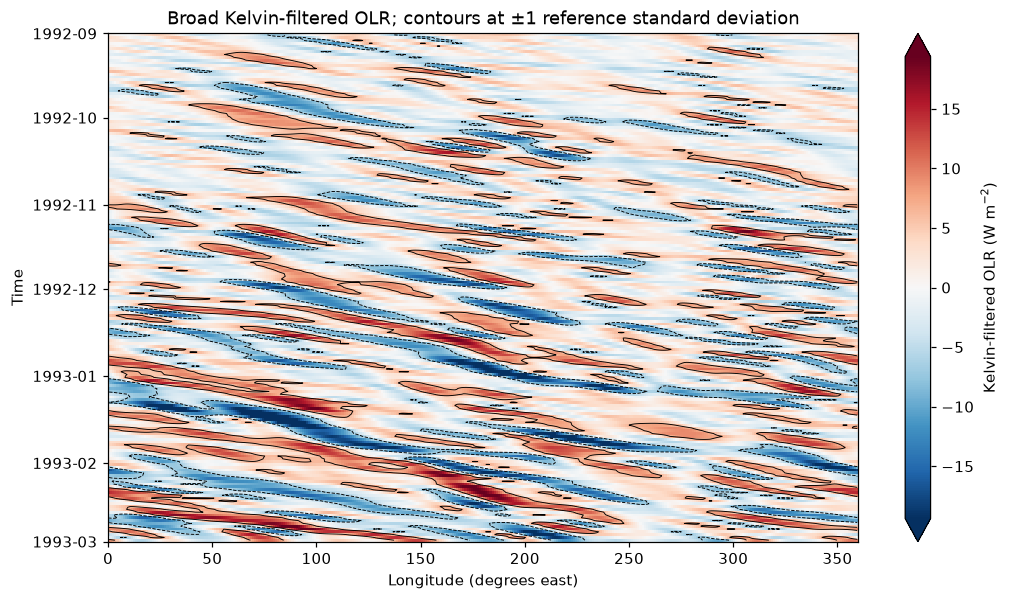

In [3]:
GENERAL_KELVIN = tw.WaveProfile(
    name="KW", aliases=("Kelvin", "Kelvin wave"),
    k_min=1, k_max=14,
    frequency_min=1 / 30, frequency_max=1 / 2.5,
    equivalent_depth_min=1, equivalent_depth_max=200,
    symmetry="symmetric", direction="eastward", curve_name="kelvin",
    description="Broad Kelvin candidate filter for event-scale fitting.",
)
wave_data = tw.filter_field(olr_anom, GENERAL_KELVIN)
hovmoller_wave_data = wave_data.mean("lat").transpose("time", "lon")
reference = hovmoller_wave_data.isel(time=slice(EDGE_BUFFER_DAYS, -EDGE_BUFFER_DAYS))
sigma = float(reference.std())  # Across reference time and all longitudes.
analysis = hovmoller_wave_data.sel(time=slice(*ANALYSIS_RANGE))
assert analysis.time[0] >= reference.time[0] and analysis.time[-1] <= reference.time[-1]

fig, ax = plt.subplots(figsize=(11, 6))
analysis.plot(ax=ax, x="lon", y="time", cmap="RdBu_r", vmin=-3*sigma, vmax=3*sigma,
              cbar_kwargs={"label": "Kelvin-filtered OLR (W m$^{-2}$)"})
analysis.plot.contour(ax=ax, x="lon", y="time", levels=[-sigma, sigma],
                      colors="k", linewidths=0.6)
ax.set(xlabel="Longitude (degrees east)", ylabel="Time",
       title="Broad Kelvin-filtered OLR; contours at ±1 reference standard deviation")
ax.invert_yaxis()
plt.show()
print(f"Interior reference standard deviation: {sigma:.2f} W m-2")


## Identify discrete enhanced-convection ridges

An event is an eight-connected component of `OLR < -1 sigma` with a peak exceeding
1.5 sigma, duration at least four sampled days, and longitude span at least 20°.
Join components across the longitude seam. Reject components touching either
analysis-time boundary, since their full duration is unknown. The window used
later for fitting includes **both signs** of OLR, not just thresholded pixels.

These deliberately simple, visible choices can merge nearby ridges or split an
intermittent ridge. They do not provide event p-values. Keep this distinction
when building a population; nearby ridges are not necessarily independent waves.


In [4]:
DETECTION_SIGMA = 1.0
PEAK_SIGMA = 1.5
MIN_DURATION_DAYS = 4
MIN_LONGITUDE_SPAN_DEG = 20

labels, _ = ndimage.label(
    analysis.values < -DETECTION_SIGMA * sigma,
    structure=np.ones((3, 3), dtype=int),
)
# Same-day and adjacent-day connections across the periodic longitude seam.
for row in range(labels.shape[0]):
    for neighbor in range(max(0, row - 1), min(labels.shape[0], row + 2)):
        left, right = labels[row, 0], labels[neighbor, -1]
        if left and right and left != right:
            labels[labels == max(left, right)] = min(left, right)

rows = []
for component in np.unique(labels[labels > 0]):
    ti, xi = np.where(labels == component)
    peak = np.argmin(analysis.values[ti, xi])
    peak_lon = float(analysis.lon[xi[peak]])
    duration = int(ti.max() - ti.min() + 1)
    event_longitudes = np.unique(analysis.lon.values[xi])
    circular_gaps = np.diff(np.r_[event_longitudes, event_longitudes[0] + 360])
    span = float(360 - circular_gaps.max())
    amplitude = float(-analysis.values[ti[peak], xi[peak]])
    if (ti.min() == 0 or ti.max() == analysis.sizes["time"] - 1
            or duration < MIN_DURATION_DAYS or span < MIN_LONGITUDE_SPAN_DEG
            or amplitude < PEAK_SIGMA * sigma):
        continue
    rows.append(dict(
        event_id=int(component), peak_time=analysis.time.values[ti[peak]],
        peak_lon_deg=peak_lon, duration_days=duration, span_deg=span,
        peak_amplitude_W_m2=amplitude,
    ))

events = pd.DataFrame(rows)
if events.empty:
    raise RuntimeError("No candidates meet the stated thresholds; inspect the Hovmöller.")
events = events.sort_values("peak_time").reset_index(drop=True)
print(f"{len(events)} amplitude-selected candidate ridges")
events


37 amplitude-selected candidate ridges


,event_id,peak_time,peak_lon_deg,duration_days,span_deg,peak_amplitude_W_m2
0,4,1992-09-04 12:00:00,109.5,5,42.0,11.538904
1,16,1992-09-26 12:00:00,88.5,17,95.0,13.126056
2,31,1992-10-03 12:00:00,261.5,5,45.0,11.048784
3,35,1992-10-07 12:00:00,188.5,11,62.0,18.326148
4,41,1992-10-11 12:00:00,168.5,4,29.0,15.127024
5,43,1992-10-20 12:00:00,158.5,10,65.0,10.764333
6,47,1992-10-30 12:00:00,125.5,6,47.0,12.198087
7,51,1992-10-31 12:00:00,176.5,4,38.0,10.951222
8,60,1992-11-07 12:00:00,334.5,9,84.0,13.134418
9,63,1992-11-10 12:00:00,192.5,6,57.0,15.070828


## Radon phase speed, then wavelength and implied frequency

For trial speed $c$ and longitudinal offset $s$, evaluate a discrete Radon line sum
of the **signed** field along $x=s+c(t-t_0)$:

$$R_c(s)=\sum_t w_t q[s+c(t-t_0),t].$$

Time weights sum to one. All trials use the same time samples, and longitude
interpolation is periodic. This is a slope-parameterized Radon/slant-stack,
implemented directly without an image-rotation convention or a scikit-image
dependency. Maximize normalized coherent power
$\sum_s w_s R_c^2 / \sum_{s,t}w_s w_t q^2$; it lies between zero and one and is
**not** a confidence level. Applying this to an envelope instead would estimate
packet propagation rather than the carrier phase speed.

Fit `constant + linear offset + a cos(K lambda) + b sin(K lambda)` to the best
aligned profile, using Gaussian spatial weights to emphasize the target event.
Scan continuous global wavenumber $K$; this is a finite-window wavelength estimate,
not an integer global Fourier mode. The fitted constant and slope are nuisance
terms, and spatial $R^2$ measures improvement over those terms alone.

At the equator, $k=K/a$, $f=cK\,86400/(2\pi a)$, $\omega=2\pi f/86400$, and
$h_{\rm apparent}=c^2/g$. No background-wind correction is made. Thus $f$ and
$\omega$ are **implied by the translating-wave assumption**, not independent
frequency measurements. Windows containing overlapping carriers or fewer than
one spatial cycle may not identify $K$ reliably.

Methodological context: [Mayta et al. (2024)](https://doi.org/10.1002/asl.1215)
describe Radon phase speeds and Hilbert envelopes. The event thresholds, normalized
line-sum implementation, and harmonic wavelength fit here are pilot choices.


In [5]:
def fit_radon_event(field, center_time, center_lon, *, speed_grid, k_grid,
                    half_window_days, offset_half_width_deg, spatial_weight_width_deg):
    """Fit a translating carrier in a daily global field with dims (time, lon).

    Speeds are m/s; k_grid contains global cycles per 360 degrees. Return a
    scalar-result dict and diagnostic arrays. No dispersion relation is fitted.
    """
    center_time = np.datetime64(center_time)
    half_window = np.timedelta64(half_window_days, "D")
    patch = field.sel(time=slice(center_time - half_window, center_time + half_window))
    if patch.sizes["time"] != 2 * half_window_days + 1:
        raise ValueError("The full fitting window is not available.")
    tau_days = (patch.time.values - center_time) / np.timedelta64(1, "D")
    longitude = patch.lon.values
    spacing = float(longitude[1] - longitude[0])
    offsets = np.arange(-offset_half_width_deg, offset_half_width_deg + spacing/2, spacing)
    wt = np.hanning(patch.sizes["time"])
    wt /= wt.sum()
    ws = np.exp(-0.5 * (offsets / spatial_weight_width_deg)**2)
    profiles, coherence = [], []
    for speed in speed_grid:
        degrees_per_day = speed * 86400 / METERS_PER_DEGREE
        aligned = np.array([
            np.interp(center_lon + offsets + degrees_per_day * lag,
                      longitude, values, period=360)
            for lag, values in zip(tau_days, patch.values)
        ])
        profile = wt @ aligned
        energy = np.sum(ws * (wt @ aligned**2))
        profiles.append(profile)
        coherence.append(np.sum(ws * profile**2) / energy if energy > 0 else 0.0)
    best_speed_index = int(np.argmax(coherence))
    speed = float(speed_grid[best_speed_index])
    profile = profiles[best_speed_index]

    radians = np.deg2rad(offsets)
    baseline = np.column_stack([np.ones_like(radians), radians])
    sqrt_ws = np.sqrt(ws)
    beta = np.linalg.lstsq(baseline * sqrt_ws[:, None], profile * sqrt_ws, rcond=None)[0]
    baseline_sse = np.sum(ws * (profile - baseline @ beta)**2)
    spatial_r2, fitted_profiles = [], []
    for K in k_grid:
        design = np.column_stack([baseline, np.cos(K * radians), np.sin(K * radians)])
        beta = np.linalg.lstsq(design * sqrt_ws[:, None], profile * sqrt_ws, rcond=None)[0]
        fitted = design @ beta
        spatial_r2.append(1 - np.sum(ws * (profile - fitted)**2) / baseline_sse
                          if baseline_sse > 0 else 0.0)
        fitted_profiles.append(fitted)
    best_k_index = int(np.argmax(spatial_r2))
    K = float(k_grid[best_k_index])
    frequency = speed * 86400 * K / (2 * np.pi * EARTH_RADIUS_M)
    result = dict(
        phase_speed_m_s=speed, K_global=K, k_rad_m=K / EARTH_RADIUS_M,
        frequency_cpd=frequency, omega_rad_s=2*np.pi*frequency/86400,
        period_days=1/frequency, h_apparent_m=speed**2/GRAVITY_M_S2,
        radon_coherence=float(coherence[best_speed_index]),
        spatial_r2=float(spatial_r2[best_k_index]),
        cycles_in_window=K * np.ptp(offsets) / 360,
        speed_at_search_edge=best_speed_index in (0, len(speed_grid)-1),
        k_at_search_edge=best_k_index in (0, len(k_grid)-1),
    )
    diagnostic = dict(
        offsets=offsets, profile=profile, fitted_profile=fitted_profiles[best_k_index],
        speed_grid=speed_grid, coherence=np.array(coherence),
        k_grid=k_grid, spatial_r2=np.array(spatial_r2),
    )
    return result, diagnostic


# These choices remain visible here rather than hidden in function defaults.
SPEED_GRID = np.arange(2.0, 50.01, 0.2)  # Encloses the filter's 3.1--44.3 m/s range.
K_GRID = np.arange(1.0, 14.001, 0.05)
FIT_OPTIONS = dict(
    speed_grid=SPEED_GRID, k_grid=K_GRID, half_window_days=10,
    offset_half_width_deg=90, spatial_weight_width_deg=45,
)
MIN_RADON_COHERENCE = 0.3
MIN_SPATIAL_R2 = 0.5
MIN_CYCLES_IN_WINDOW = 1.0


## A known translating packet checks sign, scale and the longitude seam

Use a noninteger wavenumber and a packet centered near 0/360°. The same estimator
must recover the prescribed speed and representative wavelength. This checks the
estimator, not the completeness or false-alarm rate of the observational detector.


In [6]:
known_speed = 15.0
known_K = 6.4
synthetic_lon = np.arange(0.5, 360, 1)
synthetic_days = np.arange(-30, 31)
synthetic_center_time = np.datetime64("2000-02-01T12:00:00")
moving_lon = 359.5 + known_speed * 86400 / METERS_PER_DEGREE * synthetic_days[:, None]
distance_deg = (synthetic_lon[None, :] - moving_lon + 180) % 360 - 180
synthetic = xr.DataArray(
    np.exp(-0.5*(distance_deg/40)**2 - 0.5*(synthetic_days[:, None]/8)**2)
    * np.cos(known_K * np.deg2rad(distance_deg)),
    dims=("time", "lon"),
    coords={"time": synthetic_center_time + synthetic_days.astype("timedelta64[D]"),
            "lon": synthetic_lon},
)
synthetic_fit, _ = fit_radon_event(
    synthetic, synthetic_center_time, 359.5, **FIT_OPTIONS
)
assert abs(synthetic_fit["phase_speed_m_s"] - known_speed) <= 0.6
assert abs(synthetic_fit["K_global"] - known_K) <= 0.3
print(f"Prescribed: c={known_speed:.1f} m/s, K={known_K:.2f}")
print(f"Recovered:  c={synthetic_fit['phase_speed_m_s']:.1f} m/s, "
      f"K={synthetic_fit['K_global']:.2f}, f={synthetic_fit['frequency_cpd']:.3f} cycles/day")


Prescribed: c=15.0 m/s, K=6.40
Recovered:  c=15.0 m/s, K=6.40, f=0.207 cycles/day


## Fit every candidate and retain quality flags

Fit the surrounding signed field, including suppressed-convection phases. Report
all candidates; do not clip depths to the detection filter's limits. The pilot
quality flag requires interior search optima, one spatial cycle across the fitting
window, sufficient coherence/spatial fit, and an implied frequency inside the
candidate band. These are descriptive screens, not uncertainty estimates.


In [7]:
fit_rows, diagnostics = [], {}
for event in events.itertuples(index=False):
    fit, diagnostic = fit_radon_event(
        hovmoller_wave_data, event.peak_time, event.peak_lon_deg, **FIT_OPTIONS
    )
    fit_rows.append(fit)
    diagnostics[event.event_id] = diagnostic

event_fits = pd.concat([events, pd.DataFrame(fit_rows)], axis=1)
event_fits["pilot_quality_ok"] = (
    ~event_fits.speed_at_search_edge & ~event_fits.k_at_search_edge
    & (event_fits.cycles_in_window >= MIN_CYCLES_IN_WINDOW)
    & (event_fits.radon_coherence >= MIN_RADON_COHERENCE)
    & (event_fits.spatial_r2 >= MIN_SPATIAL_R2)
    & event_fits.frequency_cpd.between(
        GENERAL_KELVIN.frequency_min, GENERAL_KELVIN.frequency_max
    )
)
print(f"{event_fits.pilot_quality_ok.sum()} / {len(event_fits)} candidates pass pilot screens")
event_fits


27 / 37 candidates pass pilot screens


,event_id,peak_time,peak_lon_deg,duration_days,span_deg,peak_amplitude_W_m2,phase_speed_m_s,K_global,k_rad_m,frequency_cpd,omega_rad_s,period_days,h_apparent_m,radon_coherence,spatial_r2,cycles_in_window,speed_at_search_edge,k_at_search_edge,pilot_quality_ok
0,4,1992-09-04 12:00:00,109.5,5,42.0,11.538904,10.2,3.55,5.572117e-07,0.078155,0.000006,12.795161,10.609127,0.643429,0.425161,1.775,False,False,False
1,16,1992-09-26 12:00:00,88.5,17,95.0,13.126056,6.2,3.95,6.199961e-07,0.052858,0.000004,18.918447,3.919789,0.719593,0.748280,1.975,False,False,True
2,31,1992-10-03 12:00:00,261.5,5,45.0,11.048784,15.8,3.00,4.708831e-07,0.102307,0.000007,9.774531,25.456196,0.508843,0.778025,1.500,False,False,True
3,35,1992-10-07 12:00:00,188.5,11,62.0,18.326148,6.0,3.15,4.944273e-07,0.040793,0.000003,24.513903,3.670978,0.497730,0.527929,1.575,False,False,True
4,41,1992-10-11 12:00:00,168.5,4,29.0,15.127024,6.2,10.15,1.593154e-06,0.135826,0.000010,7.362351,3.919789,0.477297,0.442040,5.075,False,False,False
5,43,1992-10-20 12:00:00,158.5,10,65.0,10.764333,7.4,7.55,1.185056e-06,0.120588,0.000009,8.292693,5.583966,0.546985,0.659465,3.775,False,False,True
6,47,1992-10-30 12:00:00,125.5,6,47.0,12.198087,6.6,3.55,5.572117e-07,0.050571,0.000004,19.774340,4.441884,0.533148,0.531176,1.775,False,False,True
7,51,1992-10-31 12:00:00,176.5,4,38.0,10.951222,6.6,3.00,4.708831e-07,0.042736,0.000003,23.399635,4.441884,0.447677,0.361257,1.500,False,False,False
8,60,1992-11-07 12:00:00,334.5,9,84.0,13.134418,4.6,3.95,6.199961e-07,0.039218,0.000003,25.498777,2.157720,0.382955,0.542526,1.975,False,False,True
9,63,1992-11-10 12:00:00,192.5,6,57.0,15.070828,12.4,5.75,9.025259e-07,0.153892,0.000011,6.498075,15.679156,0.529968,0.634030,2.875,False,False,True


## Inspect one event: ridge, speed objective, and spatial wavelength

Choose the candidate with the best spatial harmonic fit among those passing the
stated screens. Each diagnostic is a
separate single-panel figure. The dashed line follows the fitted **phase speed**
through the selected negative-OLR peak. Neighboring features can affect this local
fit; agreement must be assessed from the field and both objective curves.


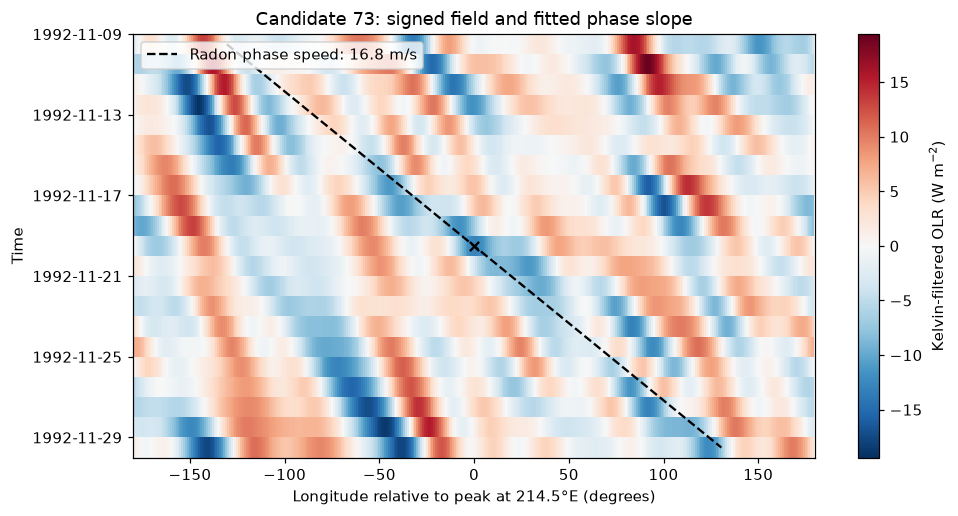

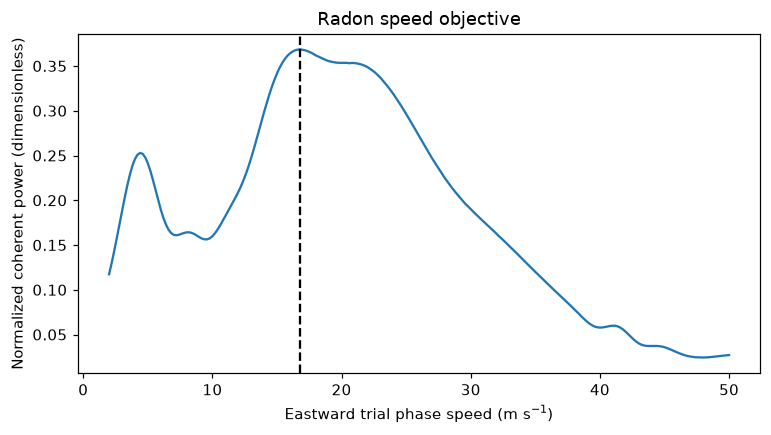

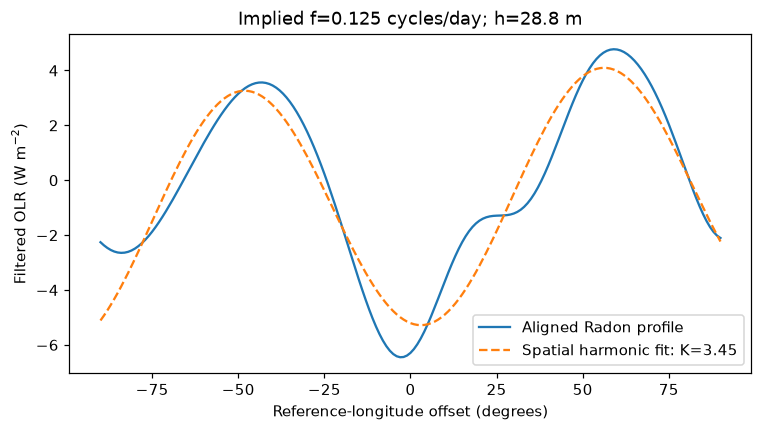

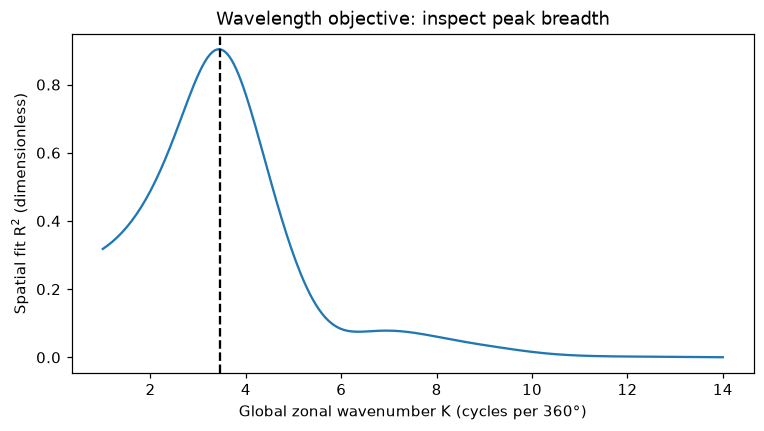

In [8]:
usable = event_fits.loc[event_fits.pilot_quality_ok]
if usable.empty:
    raise RuntimeError("No fits pass the pilot screens; inspect the catalogue before proceeding.")
chosen = usable.sort_values("spatial_r2", ascending=False).iloc[0]
diagnostic = diagnostics[int(chosen.event_id)]
center_time = chosen.peak_time.to_datetime64()
half_days = FIT_OPTIONS["half_window_days"]
patch = hovmoller_wave_data.sel(time=slice(
    center_time - np.timedelta64(half_days, "D"),
    center_time + np.timedelta64(half_days, "D"),
))
relative_lon = (patch.lon.values - chosen.peak_lon_deg + 180) % 360 - 180
patch = patch.assign_coords(lon=relative_lon).sortby("lon")
lag_days = (patch.time.values - center_time) / np.timedelta64(1, "D")

fig, ax = plt.subplots(figsize=(10, 5))
patch.plot(ax=ax, x="lon", y="time", cmap="RdBu_r", vmin=-3*sigma, vmax=3*sigma,
           cbar_kwargs={"label": "Kelvin-filtered OLR (W m$^{-2}$)"})
ax.plot(chosen.phase_speed_m_s * 86400 / METERS_PER_DEGREE * lag_days,
        patch.time, "k--", label=f"Radon phase speed: {chosen.phase_speed_m_s:.1f} m/s")
ax.scatter([0], [center_time], c="k", marker="x", zorder=5)
ax.set(xlabel=f"Longitude relative to peak at {chosen.peak_lon_deg:.1f}°E (degrees)",
       ylabel="Time", title=f"Candidate {int(chosen.event_id)}: signed field and fitted phase slope",
       xlim=(-180, 180))
ax.invert_yaxis()
ax.legend(loc="upper left")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(diagnostic["speed_grid"], diagnostic["coherence"])
ax.axvline(chosen.phase_speed_m_s, color="k", linestyle="--")
ax.set(xlabel="Eastward trial phase speed (m s$^{-1}$)",
       ylabel="Normalized coherent power (dimensionless)", title="Radon speed objective")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(diagnostic["offsets"], diagnostic["profile"], label="Aligned Radon profile")
ax.plot(diagnostic["offsets"], diagnostic["fitted_profile"], "--",
        label=f"Spatial harmonic fit: K={chosen.K_global:.2f}")
ax.set(xlabel="Reference-longitude offset (degrees)", ylabel="Filtered OLR (W m$^{-2}$)",
       title=f"Implied f={chosen.frequency_cpd:.3f} cycles/day; h={chosen.h_apparent_m:.1f} m")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(diagnostic["k_grid"], diagnostic["spatial_r2"])
ax.axvline(chosen.K_global, color="k", linestyle="--")
ax.set(xlabel="Global zonal wavenumber K (cycles per 360°)",
       ylabel="Spatial fit R$^2$ (dimensionless)", title="Wavelength objective: inspect peak breadth")
plt.show()


## Interpretation and limits of this example

- The record taper is applied before filtering, and the analysis/fitting windows
  are safely inside its flat interior. No taper correction is needed there.
- Each row describes one selected convective ridge and its local fitting window;
  it is not automatically an independent wave packet or a significant event.
- A broad spectral filter also admits other variability, including slow eastward
  signals. The fit screens do not establish Kelvin-wave identity; circulation
  structure and a calibrated detection test are needed for a scientific catalogue.
- Radon estimates phase speed. Wavelength comes from a separate spatial fit;
  frequency is inferred under translation. A good speed fit can coexist with a
  poorly determined wavelength, especially for isolated pulses or overlapping waves.
- `h_apparent_m` assumes a resting background. A model comparison needs identical
  processing and sensitivity to background advection, event thresholds, fit-window
  size, and spectral bounds. Do not interpret this small catalogue as a population PDF.
- Next validation: inject packets with known properties into realistic backgrounds,
  test recovery/false detections, estimate correlated-noise uncertainty, and group
  related ridges into packets before population inference. The grid spacings are
  numerical resolution, not confidence intervals. For ER waves use the appropriate
  dispersion branch instead of the Kelvin depth formula.
